# Old Age Home Recommendation System — Dataset Processing Notebook

**Dataset:** `All_India_Old_Age_Homes.xlsx`  
**Primary worksheet:** `Master_Data`

This notebook processes only the All-India Old Age Homes workbook. It is organized into four stages:

1. Data preprocessing, cleaning, and missing-value analysis
2. Exploratory Data Analysis (EDA)
3. Data transformation and feature engineering
4. Analysis and export of recommendation-ready data

**Important data-quality principle:** missing or zero bed capacity is not automatically treated as confirmed unavailability. Original values are preserved in the raw dataframe, and cleaning decisions are documented. The dataset is a directory, so contact details and service availability should be verified before making real-world recommendations.

Place this notebook in the same folder as `All_India_Old_Age_Homes.xlsx`, then run cells from top to bottom.

## 0. Setup and imports

In [1]:
# If needed, install dependencies in a notebook cell:
# %pip install pandas openpyxl numpy matplotlib seaborn scikit-learn

from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42


## 1. Load the workbook and inspect the source data

In [2]:
# Preferred: keep the Excel file next to this notebook.
# The /mnt/data path is a fallback for hosted notebook environments.
candidate_paths = [
    Path("dataset\All_India_Old_Age_Homes.xlsx"),
    Path("/mnt/data/All_India_Old_Age_Homes.xlsx"),
]
DATA_PATH = next((p for p in candidate_paths if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Could not find All_India_Old_Age_Homes.xlsx. "
        "Place it in the same folder as this notebook or update DATA_PATH."
    )

excel = pd.ExcelFile(DATA_PATH)
print("Workbook:", DATA_PATH.resolve())
print("Worksheets:", excel.sheet_names)

# Master_Data is the listing-level table used for this project.
df_raw = pd.read_excel(DATA_PATH, sheet_name="Master_Data")
print("Raw shape:", df_raw.shape)
display(df_raw.head())
display(pd.DataFrame({
    "column": df_raw.columns,
    "dtype": [str(dtype) for dtype in df_raw.dtypes],
    "non_null": df_raw.notna().sum().values,
    "missing": df_raw.isna().sum().values,
}))


<>:4: SyntaxWarning: invalid escape sequence '\A'
<>:4: SyntaxWarning: invalid escape sequence '\A'
C:\Users\Admin\AppData\Local\Temp\ipykernel_22852\2456077715.py:4: SyntaxWarning: invalid escape sequence '\A'
  Path("dataset\All_India_Old_Age_Homes.xlsx"),


Workbook: D:\honey\rs_1\dataset\All_India_Old_Age_Homes.xlsx
Worksheets: ['Master_Data', 'File_Summary', 'Unparsed_Sheets', 'Notes_and_Preambles', 'Unexpected_Columns']
Raw shape: (518, 20)


,S.No,State,District,City / Taluka,P.O./ Locality / Village,Home Name,Address,Pin Code,Bed Capacity,Facility Type,Telephone,Mgmt,Gender,Care Type,Source,Email,Remarks,Source_File,Source_Sheet,Source_Row
0,1,Andhra Pradesh,Anantapuramu,Anantapuramu,Narasimpalli Village,Rashtriya Seva Samithi (RASS),"Narasimpalli Village, Anantapuramu, Andhra Pradesh 515661",515661,25.0,Free,"0877-2242404, 0877-2244210",NGO,Men & Women,Basic Care,Website,rassorg@gmail.com,NaN,Old-Age-Homes-in-Andhra-Pradesh-English.xlsx,Andhra Pradesh,3
1,2,Andhra Pradesh,Bapatla,Chirala,Station Road,Mahila Mandali Chirala,"Station Road, Chirala, Bapatla, Andhra Pradesh 523155",523155,0.0,Free,9347734156,NGO,Women,Basic Care,Website,mahilamandaliclx@rediffmail.com,NaN,Old-Age-Homes-in-Andhra-Pradesh-English.xlsx,Andhra Pradesh,4
2,3,Andhra Pradesh,Chittoor,Chinnagottigallu Mandal,Chinnagotti Gallu Village,Rashtriya Seva Samithi (RASS),"Chinnagotti Gallu Village, Chinnagottigallu Mandal, Chittoor, Andhara Pradesh 517193",517193,25.0,Free,"0877-2242404, 0877-2244210",NGO,Men & Women,Basic Care,Website,rassorg@gmail.com,NaN,Old-Age-Homes-in-Andhra-Pradesh-English.xlsx,Andhra Pradesh,5
3,4,Andhra Pradesh,Chittoor,Pitchatur Mandal,Pichatur Village,Rashtriya Seva Samithi (RASS),"Pichatur Village, Pitchatur Mandal, Chittoor, Andhara Pradesh 517587",517587,25.0,Free,"0877-2242404, 0877-2244210",NGO,Men & Women,Basic Care,Website,rassorg@gmail.com,NaN,Old-Age-Homes-in-Andhra-Pradesh-English.xlsx,Andhra Pradesh,6
4,5,Andhra Pradesh,Chittoor,Srikalahasti Mandal,Thondamanpuram,Rashtriya Seva Samithi (RASS),"Thondamanpuram, Srikalahasthi Town, Srikalahasti Mandal, Chittoor, Andhara Pradesh 517644",517644,25.0,Free,"0877-2242404, 0877-2244210",NGO,Men & Women,Basic Care,Website,rassorg@gmail.com,NaN,Old-Age-Homes-in-Andhra-Pradesh-English.xlsx,Andhra Pradesh,7


,column,dtype,non_null,missing
0,S.No,int64,518,0
1,State,object,518,0
2,District,object,518,0
3,City / Taluka,object,518,0
4,P.O./ Locality / Village,object,518,0
5,Home Name,object,518,0
6,Address,object,518,0
7,Pin Code,int64,518,0
8,Bed Capacity,float64,391,127
9,Facility Type,object,518,0


### 1.1 Check row counts, uniqueness, and basic statistics

In [3]:
print(f"Rows: {len(df_raw):,}")
print(f"Columns: {df_raw.shape[1]}")
print(f"Exact duplicate rows: {df_raw.duplicated().sum():,}")
print(f"Duplicate Home Name values (case-insensitive): "
      f"{df_raw['Home Name'].astype('string').str.strip().str.casefold().duplicated().sum():,}")

display(df_raw.describe(include="all").T)


Rows: 518
Columns: 20
Exact duplicate rows: 0
Duplicate Home Name values (case-insensitive): 104


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
S.No,518.0,NaN,NaN,NaN,29.233591,30.41673,1.0,6.0,18.0,43.0,126.0
State,518,31,Kerala,126,NaN,NaN,NaN,NaN,NaN,NaN,NaN
District,518,180,Chennai,23,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City / Taluka,518,267,Chennai,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN
P.O./ Locality / Village,518,495,Velhe,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Home Name,518,419,Apna Ghar Ashram,51,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Address,518,516,"Shri Rasiklal Manikchand Dhariwal Old Age Home, Ambi Ranwadi, Block Velhe, Pune, Maharashtra 412107",2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pin Code,518.0,NaN,NaN,NaN,513395.129344,180376.893421,110017.0,401201.0,560059.5,680259.75,835302.0
Bed Capacity,391.0,NaN,NaN,NaN,60.603581,63.048934,0.0,25.0,43.0,70.0,675.0
Facility Type,518,2,Free,479,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Data preprocessing and cleaning

### 2.1 Standardize column names and text values

The original dataframe remains available as `df_raw`. The cleaned working copy is `df`. Text normalization trims whitespace, collapses repeated spaces, and converts common placeholder strings to missing values. It does not attempt to invent missing information.

In [4]:
df = df_raw.copy()

# Standardize column names while keeping meaningful names readable.
df.columns = [str(c).strip() for c in df.columns]

# Convert text-like columns to pandas string dtype, trim whitespace,
# collapse repeated whitespace, and normalize common missing-value markers.
missing_markers = {"", "na", "n/a", "nan", "none", "null", "-", "--", "not available", "not provided"}
text_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()

for col in text_cols:
    s = df[col].astype("string").str.strip()
    s = s.str.replace(r"\s+", " ", regex=True)
    df[col] = s.mask(s.str.casefold().isin(missing_markers), pd.NA)

print("Shape after text normalization:", df.shape)
display(df.head(3))


Shape after text normalization: (518, 20)


,S.No,State,District,City / Taluka,P.O./ Locality / Village,Home Name,Address,Pin Code,Bed Capacity,Facility Type,Telephone,Mgmt,Gender,Care Type,Source,Email,Remarks,Source_File,Source_Sheet,Source_Row
0,1,Andhra Pradesh,Anantapuramu,Anantapuramu,Narasimpalli Village,Rashtriya Seva Samithi (RASS),"Narasimpalli Village, Anantapuramu, Andhra Pradesh 515661",515661,25.0,Free,"0877-2242404, 0877-2244210",NGO,Men & Women,Basic Care,Website,rassorg@gmail.com,<NA>,Old-Age-Homes-in-Andhra-Pradesh-English.xlsx,Andhra Pradesh,3
1,2,Andhra Pradesh,Bapatla,Chirala,Station Road,Mahila Mandali Chirala,"Station Road, Chirala, Bapatla, Andhra Pradesh 523155",523155,0.0,Free,9347734156,NGO,Women,Basic Care,Website,mahilamandaliclx@rediffmail.com,<NA>,Old-Age-Homes-in-Andhra-Pradesh-English.xlsx,Andhra Pradesh,4
2,3,Andhra Pradesh,Chittoor,Chinnagottigallu Mandal,Chinnagotti Gallu Village,Rashtriya Seva Samithi (RASS),"Chinnagotti Gallu Village, Chinnagottigallu Mandal, Chittoor, Andhara Pradesh 517193",517193,25.0,Free,"0877-2242404, 0877-2244210",NGO,Men & Women,Basic Care,Website,rassorg@gmail.com,<NA>,Old-Age-Homes-in-Andhra-Pradesh-English.xlsx,Andhra Pradesh,5


### 2.2 Missing-value audit

,missing_count,missing_percent,dtype
Remarks,494,95.37,string
Email,254,49.03,string
Bed Capacity,127,24.52,float64
Care Type,95,18.34,string
Gender,91,17.57,string
Mgmt,65,12.55,string
Telephone,7,1.35,string
S.No,0,0.00,int64
State,0,0.00,string
District,0,0.00,string


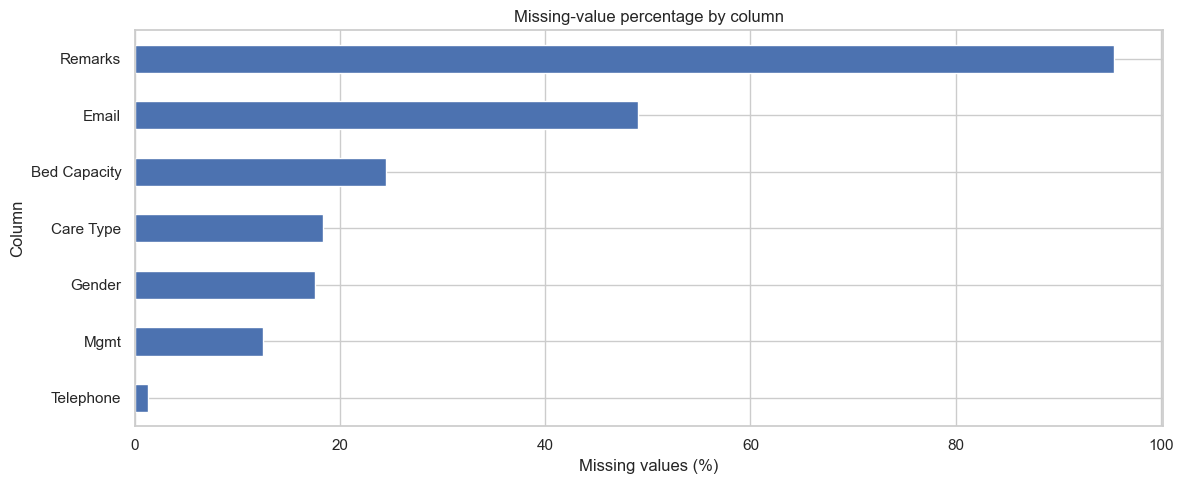

In [5]:
missing_audit = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "dtype": df.dtypes.astype(str),
}).sort_values(["missing_percent", "missing_count"], ascending=False)

display(missing_audit)

plt.figure(figsize=(12, 5))
missing_pct = missing_audit[missing_audit["missing_count"] > 0]["missing_percent"].sort_values()
if len(missing_pct):
    missing_pct.plot(kind="barh")
    plt.xlabel("Missing values (%)")
    plt.ylabel("Column")
    plt.title("Missing-value percentage by column")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values detected.")


### 2.3 Clean numeric fields and validate values

In [6]:
# Convert numeric fields safely. Invalid text becomes NaN and is audited below.
for col in ["S.No", "Pin Code", "Bed Capacity", "Source_Row"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Pin codes are identifiers, not quantities. Preserve them as nullable strings
# so leading zeroes (if any) are not lost in downstream exports.
if "Pin Code" in df.columns:
    df["Pin Code"] = (
        df["Pin Code"]
        .round()
        .astype("Int64")
        .astype("string")
        .replace("<NA>", pd.NA)
    )

# Identify suspicious values without silently deleting records.
quality_checks = {
    "missing_home_name": df["Home Name"].isna().sum(),
    "missing_state": df["State"].isna().sum(),
    "missing_district": df["District"].isna().sum(),
    "missing_address": df["Address"].isna().sum(),
    "missing_bed_capacity": df["Bed Capacity"].isna().sum(),
    "negative_bed_capacity": (df["Bed Capacity"] < 0).sum(),
    "zero_bed_capacity": (df["Bed Capacity"] == 0).sum(),
    "non_integer_bed_capacity": (
        df["Bed Capacity"].notna() &
        (df["Bed Capacity"] % 1 != 0)
    ).sum(),
    "invalid_pin_code_length": (
        df["Pin Code"].notna() &
        ~df["Pin Code"].str.fullmatch(r"\d{6}", na=False)
    ).sum(),
}
display(pd.DataFrame({"check": quality_checks.keys(), "count": quality_checks.values()}))

# Capacity values that are negative or non-integer are treated as invalid.
# Zero is retained as a reported value but flagged for verification.
invalid_capacity_mask = (
    (df["Bed Capacity"] < 0) |
    (df["Bed Capacity"].notna() & (df["Bed Capacity"] % 1 != 0))
)
df.loc[invalid_capacity_mask, "Bed Capacity"] = np.nan


,check,count
0,missing_home_name,0
1,missing_state,0
2,missing_district,0
3,missing_address,0
4,missing_bed_capacity,127
5,negative_bed_capacity,0
6,zero_bed_capacity,1
7,non_integer_bed_capacity,0
8,invalid_pin_code_length,0


### 2.4 Normalize category labels

In [7]:
def clean_category(series):
    # Trimmed/collapsed strings and case-insensitive duplicate categories.
    return series.astype("string").str.strip().str.replace(r"\s+", " ", regex=True)

for col in ["State", "District", "City / Taluka", "Facility Type", "Mgmt", "Gender", "Care Type", "Source"]:
    if col in df.columns:
        df[col] = clean_category(df[col])

# Keep a normalized key for grouping, while retaining the cleaned display label.
for col in ["State", "District", "Home Name"]:
    if col in df.columns:
        df[f"{col}_key"] = (
            df[col].astype("string").str.casefold()
            .str.replace(r"[^\w\s]", "", regex=True)
            .str.replace(r"\s+", " ", regex=True)
            .str.strip()
        )

display(df[["State", "District", "Home Name", "Facility Type", "Mgmt", "Gender", "Care Type"]].head())


,State,District,Home Name,Facility Type,Mgmt,Gender,Care Type
0,Andhra Pradesh,Anantapuramu,Rashtriya Seva Samithi (RASS),Free,NGO,Men & Women,Basic Care
1,Andhra Pradesh,Bapatla,Mahila Mandali Chirala,Free,NGO,Women,Basic Care
2,Andhra Pradesh,Chittoor,Rashtriya Seva Samithi (RASS),Free,NGO,Men & Women,Basic Care
3,Andhra Pradesh,Chittoor,Rashtriya Seva Samithi (RASS),Free,NGO,Men & Women,Basic Care
4,Andhra Pradesh,Chittoor,Rashtriya Seva Samithi (RASS),Free,NGO,Men & Women,Basic Care


### 2.5 Detect and review duplicates

In [8]:
# Exact duplicates across all columns.
exact_duplicate_count = int(df.duplicated().sum())

# Likely listing duplicates based on normalized home name + state + district.
# This is a review flag, not proof of duplication: organizations can have multiple branches.
dedupe_keys = [c for c in ["Home Name_key", "State_key", "District_key"] if c in df.columns]
df["possible_duplicate_listing"] = df.duplicated(subset=dedupe_keys, keep=False) if dedupe_keys else False

print("Exact duplicate rows:", exact_duplicate_count)
print("Rows flagged as possible same-name/same-area duplicates:",
      int(df["possible_duplicate_listing"].sum()))

possible_duplicates = df.loc[df["possible_duplicate_listing"],
    [c for c in ["Home Name", "State", "District", "Address", "Telephone", "Email", "Source_File", "Source_Row"] if c in df.columns]
].sort_values(["State", "District", "Home Name"])
display(possible_duplicates.head(50))

# Remove only exact duplicate rows. Do not automatically drop possible duplicates.
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing exact duplicates:", df.shape)


Exact duplicate rows: 0
Rows flagged as possible same-name/same-area duplicates: 44


,Home Name,State,District,Address,Telephone,Email,Source_File,Source_Row
2,Rashtriya Seva Samithi (RASS),Andhra Pradesh,Chittoor,"Chinnagotti Gallu Village, Chinnagottigallu Mandal, Chittoor, Andhara Pradesh 517193","0877-2242404, 0877-2244210",rassorg@gmail.com,Old-Age-Homes-in-Andhra-Pradesh-English.xlsx,5
3,Rashtriya Seva Samithi (RASS),Andhra Pradesh,Chittoor,"Pichatur Village, Pitchatur Mandal, Chittoor, Andhara Pradesh 517587","0877-2242404, 0877-2244210",rassorg@gmail.com,Old-Age-Homes-in-Andhra-Pradesh-English.xlsx,6
4,Rashtriya Seva Samithi (RASS),Andhra Pradesh,Chittoor,"Thondamanpuram, Srikalahasthi Town, Srikalahasti Mandal, Chittoor, Andhara Pradesh 517644","0877-2242404, 0877-2244210",rassorg@gmail.com,Old-Age-Homes-in-Andhra-Pradesh-English.xlsx,7
5,Rashtriya Seva Samithi (RASS),Andhra Pradesh,Chittoor,"Vanasthali, Anjaneya Puram, Karakambadi Village, Kadapa Trunk Road, Renigunta Mandal, Chittoor, Andhra Pradesh 517520","0877-2242404, 0877-2244210",rassorg@gmail.com,Old-Age-Homes-in-Andhra-Pradesh-English.xlsx,8
6,Rashtriya Seva Samithi (RASS),Andhra Pradesh,Chittoor,"Marrimanda, Near Papanaidupet Village, Yerpedu Mandal, Chittoor, Andhra Pradesh 517501","0877-2242404, 0877-2244210",rassorg@gmail.com,Old-Age-Homes-in-Andhra-Pradesh-English.xlsx,9
7,Rashtriya Seva Samithi (RASS),Andhra Pradesh,Chittoor,"Tapovanam, Chittoor, Andhara Pradesh 517001","0877-2242404, 0877-2244210",rassorg@gmail.com,Old-Age-Homes-in-Andhra-Pradesh-English.xlsx,10
8,Rashtriya Seva Samithi (RASS),Andhra Pradesh,Chittoor,"Gudimallam, Yerpedu Mandal, Chittoor, Andhara Pradesh 517619","0877-2242404, 0877-2244210",rassorg@gmail.com,Old-Age-Homes-in-Andhra-Pradesh-English.xlsx,11
9,Rashtriya Seva Samithi (RASS),Andhra Pradesh,Chittoor,"Karvetinagaram, Near Venugopalswamy Temple, Chittoor, Andhara Pradesh 517582","0877-2242404, 0877-2244210",rassorg@gmail.com,Old-Age-Homes-in-Andhra-Pradesh-English.xlsx,12
10,Rashtriya Seva Samithi (RASS),Andhra Pradesh,Chittoor,"BTR Colony, P.O. Mangalam, Chittoor, Andhara Pradesh 517507","0877-2242404, 0877-2244210",rassorg@gmail.com,Old-Age-Homes-in-Andhra-Pradesh-English.xlsx,13
11,Rashtriya Seva Samithi (RASS),Andhra Pradesh,Chittoor,"Velur Village, Pichatur Mandal, Chittoor, Andhara Pradesh 517587","0877-2242404, 0877-2244210",rassorg@gmail.com,Old-Age-Homes-in-Andhra-Pradesh-English.xlsx,14


Shape after removing exact duplicates: (518, 24)


### 2.6 Missing-value treatment strategy

In [9]:
# For recommendation systems, missingness can itself be useful information.
# Do not fill missing phone/email/address with fake values.
# Do not impute bed capacity with a mean: capacity is a real-world property.
# Keep missing categorical fields missing and create explicit flags for key attributes.

for col in ["Home Name", "State", "District", "Address", "Telephone", "Email",
            "Bed Capacity", "Facility Type", "Mgmt", "Gender", "Care Type"]:
    if col in df.columns:
        df[f"missing_{re.sub(r'[^A-Za-z0-9]+', '_', col).strip('_').lower()}"] = df[col].isna()

# Contact and capacity quality flags.
df["has_phone"] = df["Telephone"].notna() if "Telephone" in df.columns else False
df["has_email"] = df["Email"].notna() if "Email" in df.columns else False
df["has_address"] = df["Address"].notna() if "Address" in df.columns else False
df["capacity_needs_verification"] = (
    df["Bed Capacity"].isna() | (df["Bed Capacity"] <= 0)
) if "Bed Capacity" in df.columns else True

display(df[[c for c in ["Home Name", "State", "District", "Bed Capacity",
                         "has_phone", "has_email", "has_address",
                         "capacity_needs_verification"] if c in df.columns]].head())


,Home Name,State,District,Bed Capacity,has_phone,has_email,has_address,capacity_needs_verification
0,Rashtriya Seva Samithi (RASS),Andhra Pradesh,Anantapuramu,25.0,True,True,True,False
1,Mahila Mandali Chirala,Andhra Pradesh,Bapatla,0.0,True,True,True,True
2,Rashtriya Seva Samithi (RASS),Andhra Pradesh,Chittoor,25.0,True,True,True,False
3,Rashtriya Seva Samithi (RASS),Andhra Pradesh,Chittoor,25.0,True,True,True,False
4,Rashtriya Seva Samithi (RASS),Andhra Pradesh,Chittoor,25.0,True,True,True,False


## 3. Exploratory Data Analysis (EDA)

### 3.1 Dataset overview and coverage

In [10]:
print("Cleaned row count:", len(df))
print("Unique states/territories represented:", df["State"].nunique(dropna=True))
print("Unique districts represented:", df["District"].nunique(dropna=True))
print("Unique home names:", df["Home Name_key"].nunique(dropna=True))
print("Records with a phone number:", int(df["has_phone"].sum()))
print("Records with an email:", int(df["has_email"].sum()))
print("Records with an address:", int(df["has_address"].sum()))
print("Records whose capacity needs verification:", int(df["capacity_needs_verification"].sum()))

display(df[["State", "District", "Home Name"]].nunique().rename("unique_values").to_frame())


Cleaned row count: 518
Unique states/territories represented: 31
Unique districts represented: 179
Unique home names: 414
Records with a phone number: 511
Records with an email: 264
Records with an address: 518
Records whose capacity needs verification: 128


,unique_values
State,31
District,179
Home Name,415


### 3.2 Old age homes by state

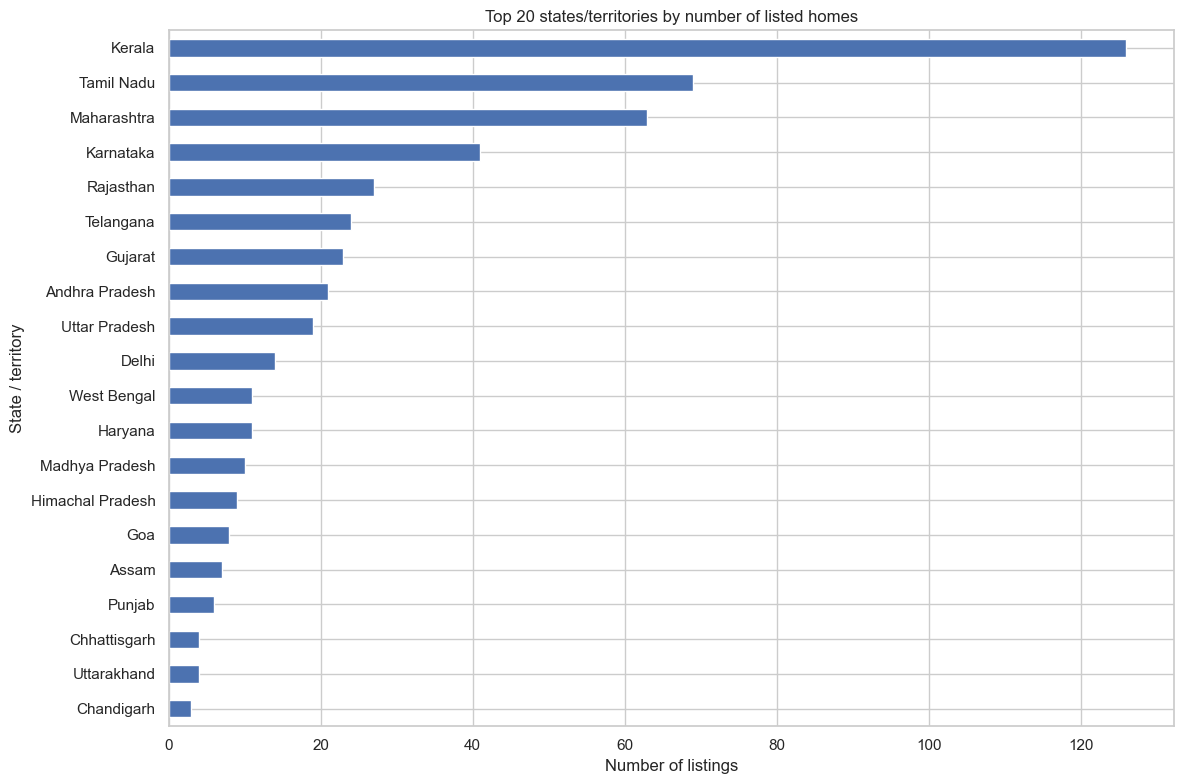

,State,Listing_Count
0,Kerala,126
1,Tamil Nadu,69
2,Maharashtra,63
3,Karnataka,41
4,Rajasthan,27
5,Telangana,24
6,Gujarat,23
7,Andhra Pradesh,21
8,Uttar Pradesh,19
9,Delhi,14


In [11]:
state_counts = df["State"].value_counts(dropna=False).drop(index=pd.NA, errors="ignore")
plt.figure(figsize=(12, 8))
state_counts.head(20).sort_values().plot(kind="barh")
plt.title("Top 20 states/territories by number of listed homes")
plt.xlabel("Number of listings")
plt.ylabel("State / territory")
plt.tight_layout()
plt.show()

display(state_counts.rename_axis("State").reset_index(name="Listing_Count").head(20))


### 3.3 Facility type, care type, management, and gender

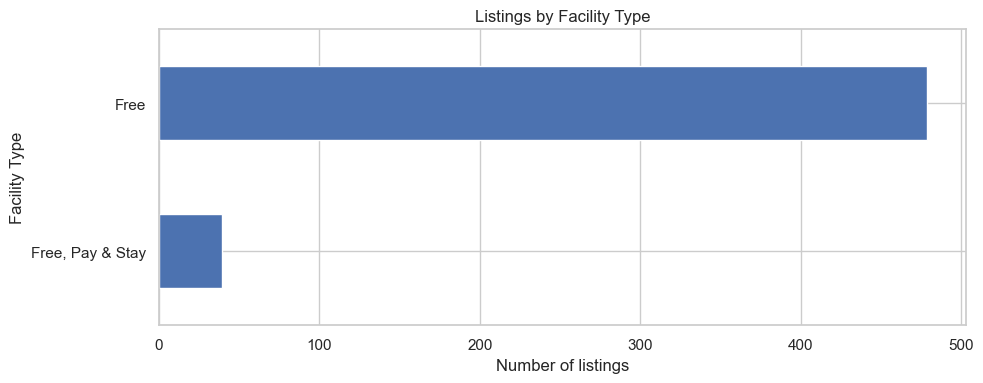

,Facility Type,Listing_Count
0,Free,479
1,"Free, Pay & Stay",39


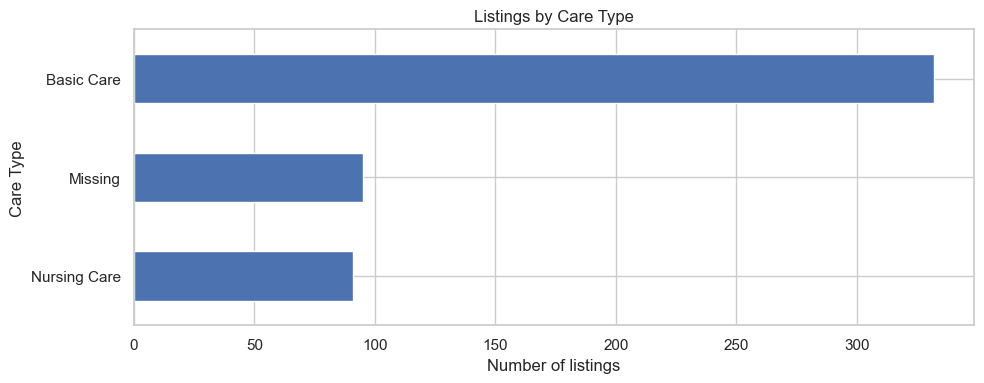

,Care Type,Listing_Count
0,Basic Care,332
1,Missing,95
2,Nursing Care,91


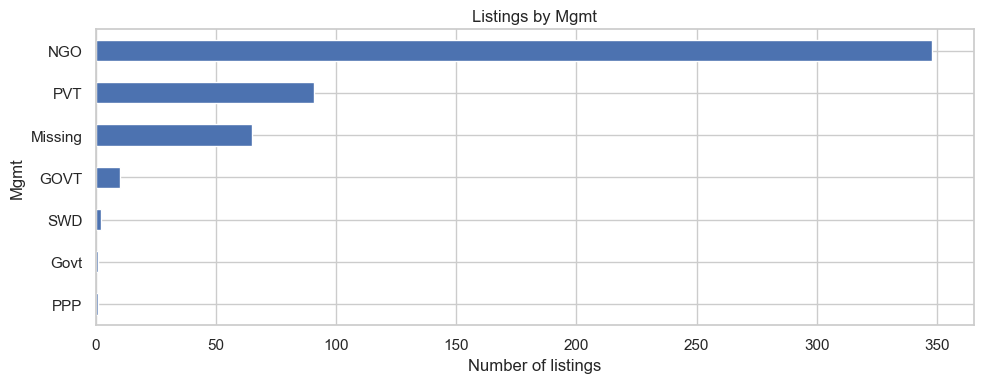

,Mgmt,Listing_Count
0,NGO,348
1,PVT,91
2,Missing,65
3,GOVT,10
4,SWD,2
5,PPP,1
6,Govt,1


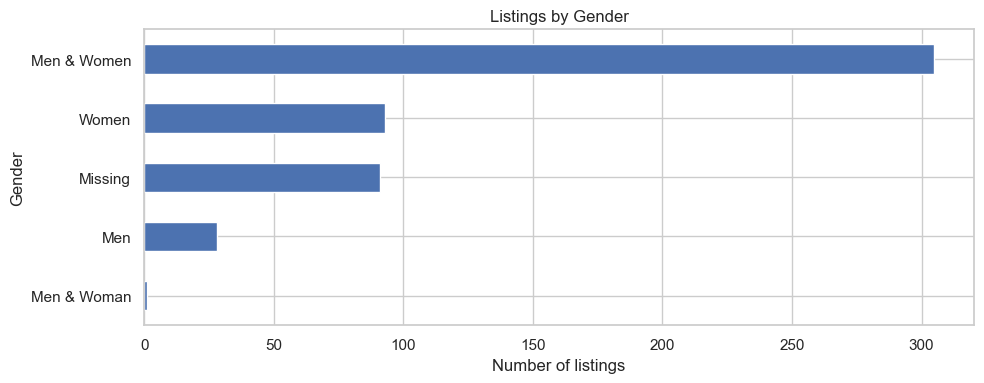

,Gender,Listing_Count
0,Men & Women,305
1,Women,93
2,Missing,91
3,Men,28
4,Men & Woman,1


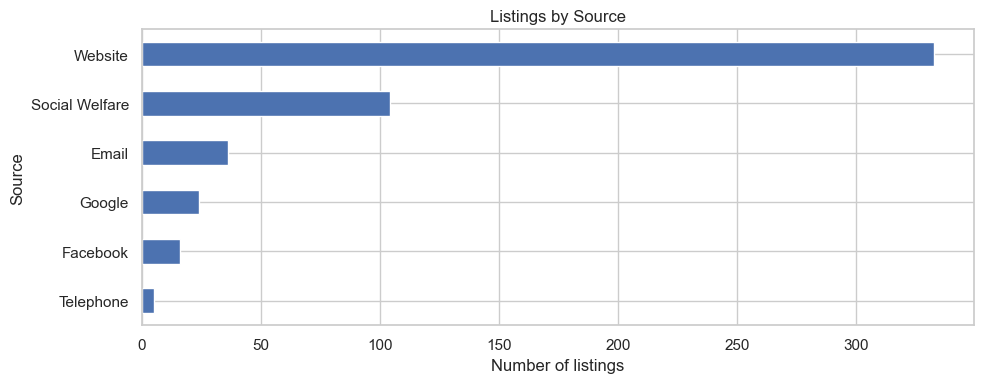

,Source,Listing_Count
0,Website,333
1,Social Welfare,104
2,Email,36
3,Google,24
4,Facebook,16
5,Telephone,5


In [12]:
categorical_eda_cols = ["Facility Type", "Care Type", "Mgmt", "Gender", "Source"]
for col in categorical_eda_cols:
    if col not in df.columns:
        continue
    counts = df[col].fillna("Missing").value_counts().head(15)
    if counts.empty:
        continue
    plt.figure(figsize=(10, max(4, 0.35 * len(counts))))
    counts.sort_values().plot(kind="barh")
    plt.title(f"Listings by {col}")
    plt.xlabel("Number of listings")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()
    display(counts.rename_axis(col).reset_index(name="Listing_Count"))


### 3.4 Bed capacity distribution

       Bed Capacity
count    391.000000
mean      60.603581
std       63.048934
min        0.000000
25%       25.000000
50%       43.000000
75%       70.000000
90%      130.000000
95%      150.000000
max      675.000000
Zero capacity values retained for review: 1


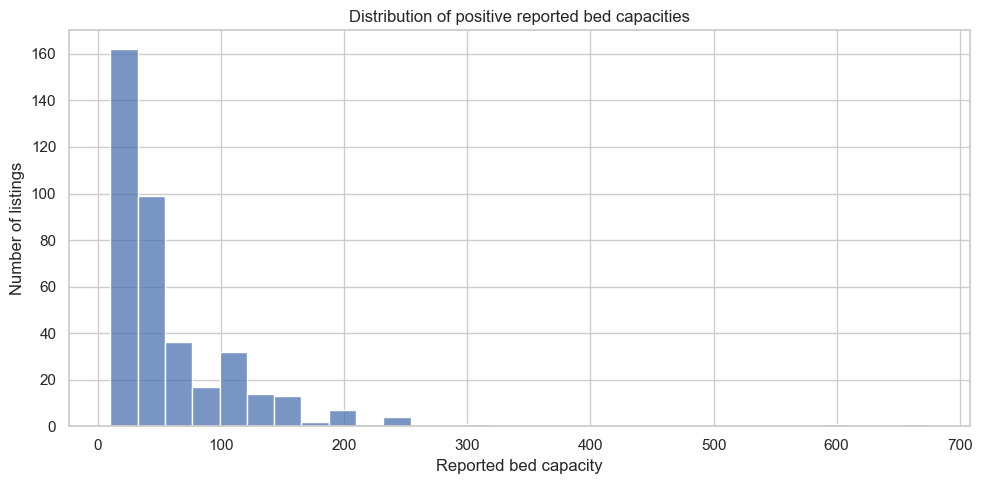

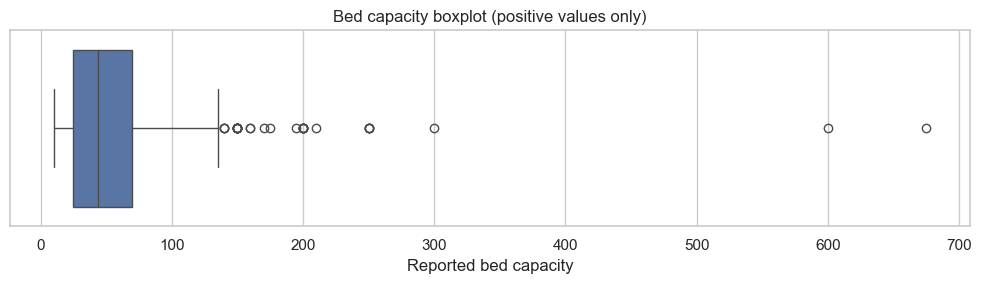

In [13]:
capacity = df["Bed Capacity"].dropna()
if not capacity.empty:
    print(capacity.describe(percentiles=[.25, .5, .75, .9, .95]).to_frame("Bed Capacity"))
    print("Zero capacity values retained for review:", int((df["Bed Capacity"] == 0).sum()))
    positive_capacity = capacity[capacity > 0]
    if not positive_capacity.empty:
        plt.figure(figsize=(10, 5))
        sns.histplot(positive_capacity, bins=30)
        plt.title("Distribution of positive reported bed capacities")
        plt.xlabel("Reported bed capacity")
        plt.ylabel("Number of listings")
        plt.tight_layout()
        plt.show()

        plt.figure(figsize=(10, 3))
        sns.boxplot(x=positive_capacity)
        plt.title("Bed capacity boxplot (positive values only)")
        plt.xlabel("Reported bed capacity")
        plt.tight_layout()
        plt.show()
else:
    print("No numeric bed capacity values available.")


### 3.5 Geographic detail: top districts within the most represented states

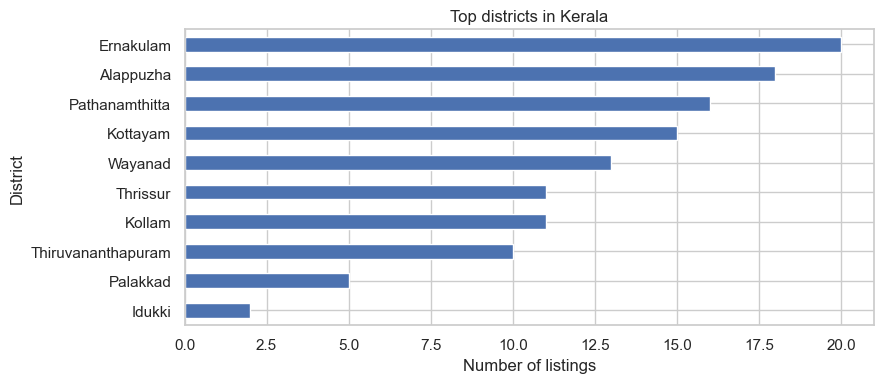

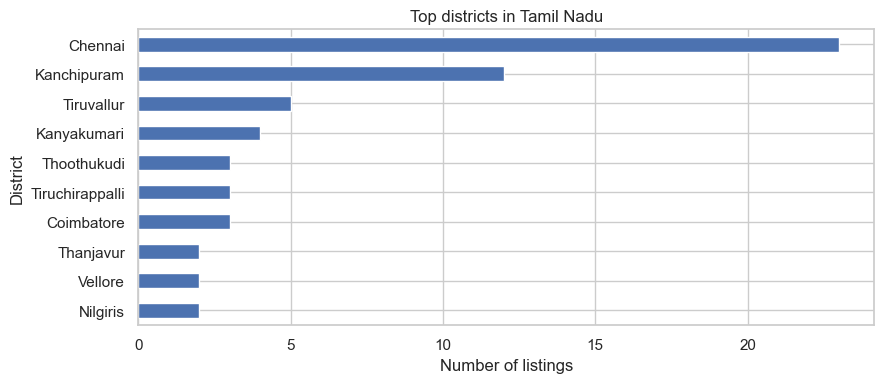

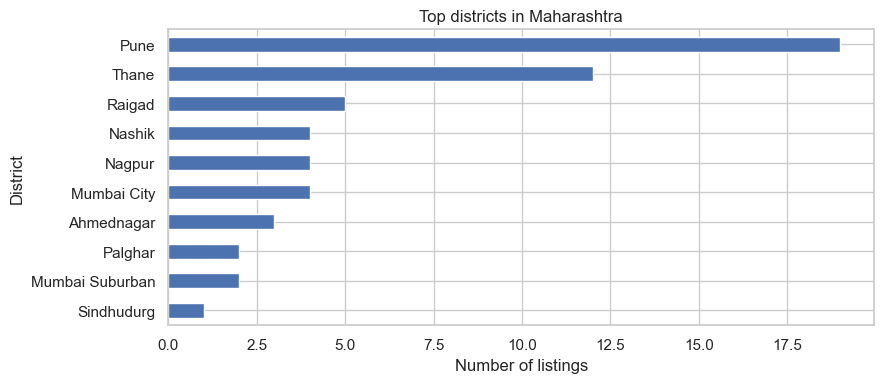

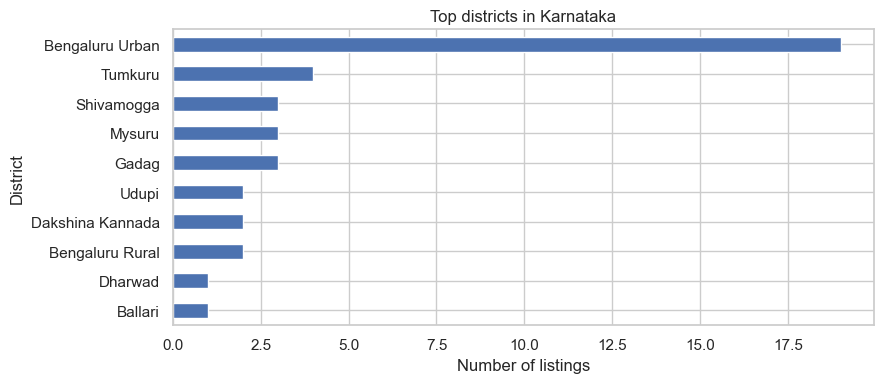

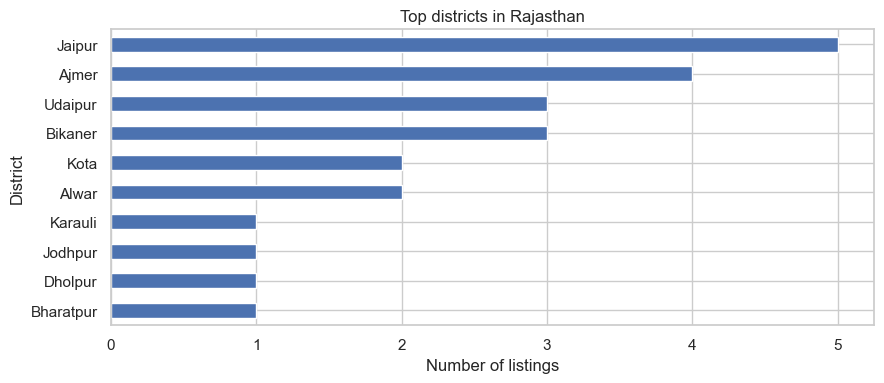

In [14]:
# For the top 5 states by listing count, show the most represented districts.
top_states = df["State"].value_counts().head(5).index.tolist()
for state in top_states:
    district_counts = (
        df.loc[df["State"] == state, "District"]
        .dropna()
        .value_counts()
        .head(10)
    )
    if district_counts.empty:
        continue
    plt.figure(figsize=(9, 4))
    district_counts.sort_values().plot(kind="barh")
    plt.title(f"Top districts in {state}")
    plt.xlabel("Number of listings")
    plt.ylabel("District")
    plt.tight_layout()
    plt.show()


### 3.6 Missingness and contactability

,Metric,Count,Percent
0,Phone available,511,98.65
1,Email available,264,50.97
2,Address available,518,100.00
3,Missing phone,7,1.35
4,Missing email,254,49.03
5,Missing address,0,0.00
6,Capacity needs verification,128,24.71


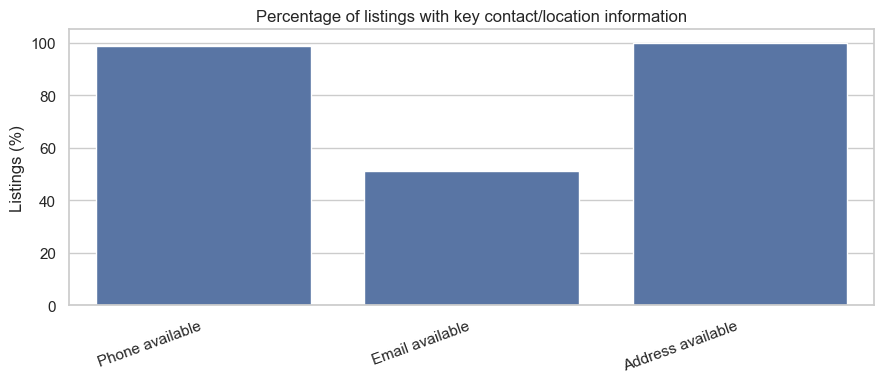

In [15]:
contact_summary = pd.DataFrame({
    "Metric": ["Phone available", "Email available", "Address available",
               "Missing phone", "Missing email", "Missing address",
               "Capacity needs verification"],
    "Count": [
        int(df["has_phone"].sum()), int(df["has_email"].sum()), int(df["has_address"].sum()),
        int((~df["has_phone"]).sum()), int((~df["has_email"]).sum()), int((~df["has_address"]).sum()),
        int(df["capacity_needs_verification"].sum())
    ]
})
contact_summary["Percent"] = (contact_summary["Count"] / len(df) * 100).round(2)
display(contact_summary)

plt.figure(figsize=(9, 4))
sns.barplot(data=contact_summary.iloc[:3], x="Metric", y="Percent")
plt.title("Percentage of listings with key contact/location information")
plt.ylabel("Listings (%)")
plt.xlabel("")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


## 4. Data transformation and feature engineering

This stage creates model-friendly features while keeping the cleaned source columns. These features support filtering and ranking, but do not imply verified service availability.

### 4.1 Standardize labels and create interpretable features

In [16]:
# Create normalized categorical features for consistent grouping/matching.
for col in ["State", "District", "City / Taluka", "Facility Type", "Mgmt", "Gender", "Care Type"]:
    if col in df.columns:
        df[f"{col}_normalized"] = (
            df[col].astype("string").str.casefold()
            .str.replace(r"\s+", " ", regex=True).str.strip()
        )

# Home name/address text for text-based similarity (combine available descriptive fields).
text_feature_cols = [c for c in ["Home Name", "Facility Type", "Care Type", "Gender", "Mgmt",
                                  "City / Taluka", "District", "State", "Address"] if c in df.columns]
df["recommendation_text"] = (
    df[text_feature_cols].fillna("").astype(str).agg(" ".join, axis=1)
    .str.replace(r"\s+", " ", regex=True).str.strip()
)

# Capacity bands are only assigned when capacity is positive.
# Thresholds are transparent heuristic bands and can be changed for the project.
def capacity_band(value):
    if pd.isna(value) or value <= 0:
        return "unknown_or_verify"
    if value <= 25:
        return "small_1_25"
    if value <= 50:
        return "medium_26_50"
    if value <= 100:
        return "large_51_100"
    return "very_large_100_plus"

df["capacity_band"] = df["Bed Capacity"].apply(capacity_band)

# Contact completeness score: count of available key contact/location fields.
contact_fields = [c for c in ["Telephone", "Email", "Address"] if c in df.columns]
df["contact_completeness_count"] = df[contact_fields].notna().sum(axis=1)
df["contact_completeness_pct"] = (
    df["contact_completeness_count"] / max(len(contact_fields), 1) * 100
).round(1)

# Basic source traceability flag; this only checks whether a source field is populated.
df["has_source_reference"] = df["Source"].notna() if "Source" in df.columns else False

display(df[[c for c in ["Home Name", "State_normalized", "District_normalized",
                         "capacity_band", "contact_completeness_count",
                         "contact_completeness_pct", "has_source_reference",
                         "recommendation_text"] if c in df.columns]].head())


,Home Name,State_normalized,District_normalized,capacity_band,contact_completeness_count,contact_completeness_pct,has_source_reference,recommendation_text
0,Rashtriya Seva Samithi (RASS),andhra pradesh,anantapuramu,small_1_25,3,100.0,True,Rashtriya Seva Samithi (RASS) Free Basic Care Men & Women NGO Anantapuramu Anantapuramu Andhra Pradesh Narasimpalli ...
1,Mahila Mandali Chirala,andhra pradesh,bapatla,unknown_or_verify,3,100.0,True,"Mahila Mandali Chirala Free Basic Care Women NGO Chirala Bapatla Andhra Pradesh Station Road, Chirala, Bapatla, Andh..."
2,Rashtriya Seva Samithi (RASS),andhra pradesh,chittoor,small_1_25,3,100.0,True,Rashtriya Seva Samithi (RASS) Free Basic Care Men & Women NGO Chinnagottigallu Mandal Chittoor Andhra Pradesh Chinna...
3,Rashtriya Seva Samithi (RASS),andhra pradesh,chittoor,small_1_25,3,100.0,True,Rashtriya Seva Samithi (RASS) Free Basic Care Men & Women NGO Pitchatur Mandal Chittoor Andhra Pradesh Pichatur Vill...
4,Rashtriya Seva Samithi (RASS),andhra pradesh,chittoor,small_1_25,3,100.0,True,Rashtriya Seva Samithi (RASS) Free Basic Care Men & Women NGO Srikalahasti Mandal Chittoor Andhra Pradesh Thondamanp...


### 4.2 One-hot encode selected categorical features (optional model input)

In [17]:
# This creates a separate numeric feature matrix for experimentation.
# Avoid one-hot encoding identifiers such as home names, phone numbers, or addresses.
one_hot_cols = [c for c in ["State_normalized", "Facility Type_normalized",
                             "Care Type_normalized", "Mgmt_normalized",
                             "Gender_normalized", "capacity_band"] if c in df.columns]

X_categorical = pd.get_dummies(
    df[one_hot_cols].fillna("unknown"),
    columns=one_hot_cols,
    dtype=int
)

print("Categorical input columns:", one_hot_cols)
print("One-hot feature matrix shape:", X_categorical.shape)
display(X_categorical.head())


Categorical input columns: ['State_normalized', 'Facility Type_normalized', 'Care Type_normalized', 'Mgmt_normalized', 'Gender_normalized', 'capacity_band']
One-hot feature matrix shape: (518, 52)


,State_normalized_andhra pradesh,State_normalized_arunachal pradesh,State_normalized_assam,State_normalized_bihar,State_normalized_chandigarh,State_normalized_chhattisgarh,"State_normalized_dadra, nagar haveli, daman and diu",State_normalized_delhi,State_normalized_goa,State_normalized_gujarat,State_normalized_haryana,State_normalized_himachal pradesh,State_normalized_jharkhand,State_normalized_karnataka,State_normalized_kerala,State_normalized_ladakh,State_normalized_madhya pradesh,State_normalized_maharashtra,State_normalized_manipur,State_normalized_meghalaya,State_normalized_mizoram,State_normalized_nagaland,State_normalized_puducherry,State_normalized_punjab,State_normalized_rajasthan,State_normalized_tamil nadu,State_normalized_telangana,State_normalized_tripura,State_normalized_uttar pradesh,State_normalized_uttarakhand,State_normalized_west bengal,Facility Type_normalized_free,"Facility Type_normalized_free, pay & stay",Care Type_normalized_basic care,Care Type_normalized_nursing care,Care Type_normalized_unknown,Mgmt_normalized_govt,Mgmt_normalized_ngo,Mgmt_normalized_ppp,Mgmt_normalized_pvt,Mgmt_normalized_swd,Mgmt_normalized_unknown,Gender_normalized_men,Gender_normalized_men & woman,Gender_normalized_men & women,Gender_normalized_unknown,Gender_normalized_women,capacity_band_large_51_100,capacity_band_medium_26_50,capacity_band_small_1_25,capacity_band_unknown_or_verify,capacity_band_very_large_100_plus
0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0
1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,1,0
2,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0
3,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0
4,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0


### 4.3 TF-IDF text features for content-based similarity (optional)

In [18]:
# TF-IDF is useful for matching free-text user needs with listing descriptions.
# It is a text representation, not a trained recommender by itself.
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

text_series = df["recommendation_text"].fillna("").astype(str)
tfidf = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    max_features=5000,
    stop_words="english"
)
tfidf_matrix = tfidf.fit_transform(text_series)

print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))


TF-IDF matrix shape: (518, 5000)
Vocabulary size: 5000


## 5. Analysis for recommendation-system readiness

### 5.1 Data readiness scorecard

,Data Quality Indicator,Percent
0,Home name present,100.00
1,State present,100.00
2,District present,100.00
3,Address present,100.00
4,Phone present,98.65
5,Email present,50.97
6,Positive reported capacity,75.29
7,Care type present,81.66
8,Facility type present,100.00


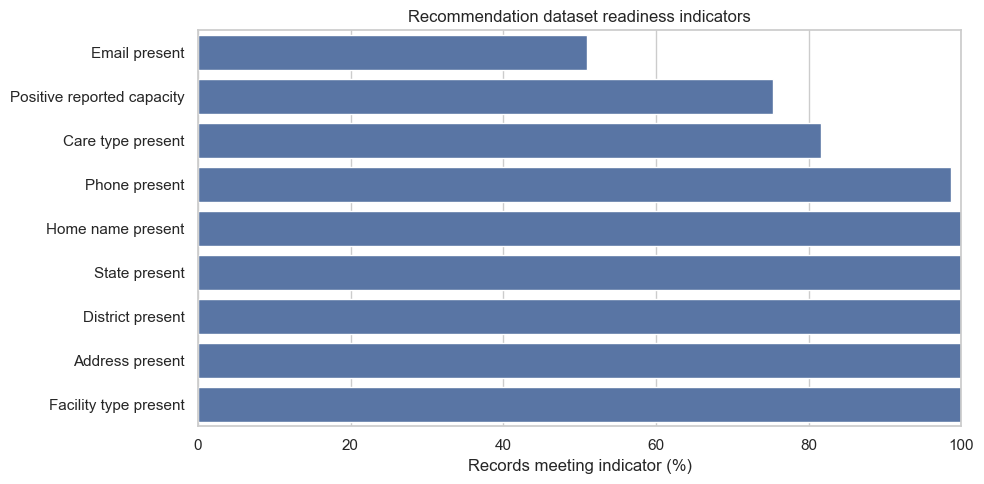

In [19]:
n = max(len(df), 1)
readiness = pd.DataFrame([
    ("Home name present", df["Home Name"].notna().mean() * 100),
    ("State present", df["State"].notna().mean() * 100),
    ("District present", df["District"].notna().mean() * 100),
    ("Address present", df["Address"].notna().mean() * 100),
    ("Phone present", df["has_phone"].mean() * 100),
    ("Email present", df["has_email"].mean() * 100),
    ("Positive reported capacity", (df["Bed Capacity"] > 0).mean() * 100),
    ("Care type present", df["Care Type"].notna().mean() * 100),
    ("Facility type present", df["Facility Type"].notna().mean() * 100),
], columns=["Data Quality Indicator", "Percent"])
readiness["Percent"] = readiness["Percent"].round(2)
display(readiness)

plt.figure(figsize=(10, 5))
sns.barplot(data=readiness.sort_values("Percent"), x="Percent", y="Data Quality Indicator")
plt.xlim(0, 100)
plt.title("Recommendation dataset readiness indicators")
plt.xlabel("Records meeting indicator (%)")
plt.ylabel("")
plt.tight_layout()
plt.show()


### 5.2 Explore candidate recommendation filters

In [20]:
# These are exploratory counts, not claims that every listing is currently available.
filter_summary = {}
for col in ["State", "Facility Type", "Care Type", "Gender", "Mgmt", "capacity_band"]:
    if col in df.columns:
        filter_summary[col] = int(df[col].notna().sum())

print("Records with usable values for potential filters:")
display(pd.DataFrame({"Feature": filter_summary.keys(),
                      "Non_missing_records": filter_summary.values(),
                      "Coverage_percent": [round(v / n * 100, 2) for v in filter_summary.values()]}))

# Example: inspect listings for a state selected by the analyst.
# Change TARGET_STATE to a value shown in df['State'].value_counts().
TARGET_STATE = None  # e.g., "Maharashtra"
if TARGET_STATE:
    subset = df[df["State"].astype("string").str.casefold() == TARGET_STATE.casefold()]
    display(subset[[c for c in ["Home Name", "District", "City / Taluka", "Facility Type",
                                 "Care Type", "Gender", "Bed Capacity", "Telephone", "Email"] if c in subset.columns]])
    print("Listings in selected state:", len(subset))


Records with usable values for potential filters:


,Feature,Non_missing_records,Coverage_percent
0,State,518,100.00
1,Facility Type,518,100.00
2,Care Type,423,81.66
3,Gender,427,82.43
4,Mgmt,453,87.45
5,capacity_band,518,100.00


### 5.3 Example content-based recommendation function

In [21]:
def recommend_by_text(query, top_n=10, state=None, care_type=None):
    """Return listings most similar to a free-text requirement.

    Optional state/care_type filters use the cleaned source labels.
    Verify all recommended details with the home before relying on them.
    """
    candidates = df.copy()
    if state:
        candidates = candidates[
            candidates["State"].astype("string").str.casefold() == str(state).casefold()
        ]
    if care_type:
        candidates = candidates[
            candidates["Care Type"].astype("string").str.casefold() == str(care_type).casefold()
        ]

    if candidates.empty:
        return pd.DataFrame(columns=["Home Name", "State", "District", "similarity_score"])

    # Transform the query using the same vocabulary fitted to the dataset.
    query_vec = tfidf.transform([query])
    candidate_positions = candidates.index.to_numpy()
    scores = cosine_similarity(query_vec, tfidf_matrix[candidate_positions]).ravel()

    candidates = candidates.copy()
    candidates["similarity_score"] = scores
    result_cols = [c for c in ["Home Name", "State", "District", "City / Taluka",
                                "Facility Type", "Care Type", "Gender", "Bed Capacity",
                                "Telephone", "Email", "Address", "Source", "similarity_score"]
                   if c in candidates.columns]
    return candidates.sort_values("similarity_score", ascending=False)[result_cols].head(top_n)

# Example query — edit to suit your use case.
display(recommend_by_text(
    query="free basic care senior citizens home for women",
    top_n=10
))


,Home Name,State,District,City / Taluka,Facility Type,Care Type,Gender,Bed Capacity,Telephone,Email,Address,Source,similarity_score
460,AMS AV Home for Senior Citizens,Telangana,Hyderabad,Hyderabad,"Free, Pay & Stay",Basic Care,Men & Women,20.0,040-23702321,<NA>,"Dr. A.V.Home for Senior Citizens, Durgabai Deshmukh Mahila Sabha (Andhra Mahila Sabha), Plot No.59, Sundernagar Colo...",Website,0.277153
114,Anand Ashram,Karnataka,Bengaluru Urban,Bengaluru,"Free, Pay & Stay",Basic Care,Men & Women,28.0,080-26784621,info@anandashram.co.in,"The Social Workers Brotherhood, Senior Citizens Home 53/7, Bannerghatta Road, Bengaluru Urban, Karnataka 560029",Website,0.257790
429,Janaki Ammal Vijayaraghavachariar Memorial Senior Citizens Home,Tamil Nadu,Kanchipuram,Madhurandhagam,Free,Basic Care,Men & Women,20.0,"9444793505, 9444333529","vpdr@sevalaya.org, contact@sevalaya.org","C/O. Sevalaya Old Age Home, Telephone Exchange Street, Zamin Endathur Village, Madhurandhagam Taluk, Kanchipuram, Ta...",Website,0.245818
399,Anandam Home For Senior Citizens,Tamil Nadu,Chennai,Chennai,Free,Basic Care,Men & Women,105.0,"044-26860099, 9841001925",anandamtrust2003@gmail.com,"Anna Street, Gangai Nagar, Kallikuppam, Ambattur, Chennai, Tamil Nadu 600053",Website,0.243021
127,Villa Maria Senior Citizens Home,Karnataka,Bengaluru Urban,Bengaluru,"Free, Pay & Stay",Basic Care,Women,88.0,8970775242,mariasevasangha@gmail.com,"Maria Seva Sangha, No. 28, K No. 335, Athithi Layout, S.T. Halli, MSS Layout, Anadapura, Bengaluru Urban, Karnataka ...",Website,0.240963
402,M.S.P.C. Senior Citizens Home,Tamil Nadu,Chennai,Chennai,Free,<NA>,<NA>,23.0,"044-25951521, 044-25961521",contact@mspcchildrenhome.com,"The Madras Society for the Protection of Children, Old No. 288, New No. 891, Thiruvottiyur High Road, Old Washermanp...",Website,0.228492
455,Senior Citizens Home,Tamil Nadu,Villupuram,Villupuram,Free,<NA>,<NA>,43.0,0761-654123987,karunalaya1989@gmail.com,"Kandhamanadi, Villupuram Taluk, Villupuram, Tamil Nadu 610001",Website,0.224000
230,Navajeevodhayam Missions India,Kerala,Pathanamthitta,Konni,Free,Basic Care,Women,25.0,"0468-2205005, 9961632392",<NA>,"Home For Senior Citizens & Spirituality Centre, Cherimukku, Konni, Pathanamthitta, Kerala 689691",Social Welfare,0.210455
416,Sevalaya's V T Shanthi Memorial Senior Citizens Home,Tamil Nadu,Dharmapuri,Dharmapuri,Free,Basic Care,Men & Women,20.0,"9444793505, 9444333529","vpdr@sevalaya.org, contact@sevalaya.org","C/O. Sevalaya Old Age Home, 4/1168, Errapatti, Village, A Jettihalli Nallamballi, Taluk, Dharmapuri, Tamil Nadu 6368...",Website,0.208096
513,Kheya Senior Citizens’ Home,West Bengal,Purba Medinipur,Purba Medinipur,Free,Basic Care,Women,25.0,"7364029438, 8158829761","vlncontai@yahoo.in, vlnvhmr@yahoo.in","Vivakananda Loksiksha Niketan, Plot No. 1026, Khatian No. 305/2, J.L No. 575, Mouza Faridpur, P.S. Contai, Purba Med...",Website,0.201527


### 5.4 Correlation and capacity analysis

,Bed Capacity,contact_completeness_count,contact_completeness_pct
Bed Capacity,1.000000,0.105625,0.105629
contact_completeness_count,0.105625,1.000000,1.000000
contact_completeness_pct,0.105629,1.000000,1.000000


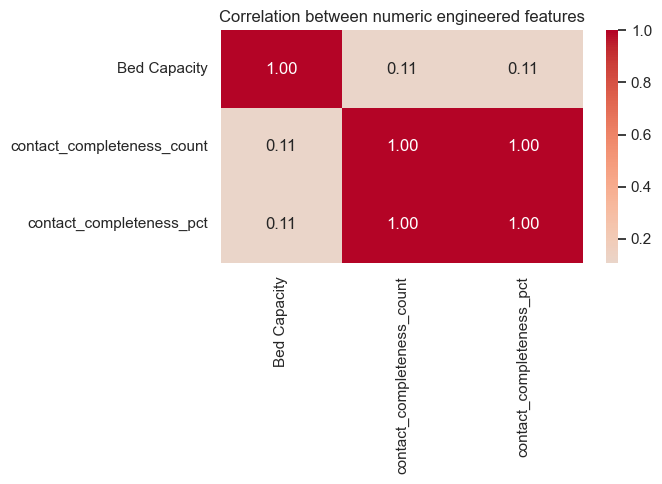

In [22]:
# Capacity is the main numeric feature in this dataset; S.No and Pin Code are identifiers,
# so they are intentionally excluded from correlation analysis.
numeric_cols = [c for c in ["Bed Capacity", "contact_completeness_count", "contact_completeness_pct"]
                if c in df.columns]
numeric_df = df[numeric_cols].apply(pd.to_numeric, errors="coerce")
if numeric_df.shape[1] >= 2 and numeric_df.notna().sum().min() >= 2:
    corr = numeric_df.corr(numeric_only=True)
    display(corr)
    plt.figure(figsize=(7, 5))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
    plt.title("Correlation between numeric engineered features")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numeric feature variation for a meaningful correlation matrix.")


## 6. Export cleaned and engineered datasets

In [23]:
OUTPUT_DIR = Path("processed_old_age_home_data")
OUTPUT_DIR.mkdir(exist_ok=True)

# Export cleaned listings with engineered columns and a separate one-hot feature matrix.
cleaned_path = OUTPUT_DIR / "old_age_homes_cleaned_engineered.csv"
features_path = OUTPUT_DIR / "old_age_homes_one_hot_features.csv"
missing_path = OUTPUT_DIR / "old_age_homes_missing_value_audit.csv"
readiness_path = OUTPUT_DIR / "old_age_homes_data_readiness.csv"
duplicate_path = OUTPUT_DIR / "old_age_homes_possible_duplicates_for_review.csv"

df.to_csv(cleaned_path, index=False, encoding="utf-8-sig")
X_categorical.to_csv(features_path, index=False, encoding="utf-8-sig")
missing_audit.to_csv(missing_path, encoding="utf-8-sig")
readiness.to_csv(readiness_path, index=False, encoding="utf-8-sig")
possible_duplicates.to_csv(duplicate_path, index=False, encoding="utf-8-sig")

print("Saved files:")
for p in [cleaned_path, features_path, missing_path, readiness_path, duplicate_path]:
    print(f"- {p.resolve()} ({p.stat().st_size:,} bytes)")


Saved files:
- D:\honey\rs_1\processed_old_age_home_data\old_age_homes_cleaned_engineered.csv (352,219 bytes)
- D:\honey\rs_1\processed_old_age_home_data\old_age_homes_one_hot_features.csv (55,832 bytes)
- D:\honey\rs_1\processed_old_age_home_data\old_age_homes_missing_value_audit.csv (543 bytes)
- D:\honey\rs_1\processed_old_age_home_data\old_age_homes_data_readiness.csv (258 bytes)
- D:\honey\rs_1\processed_old_age_home_data\old_age_homes_possible_duplicates_for_review.csv (9,575 bytes)


## 7. Automatically generated analysis summary

In [24]:
def top_values(series, k=5):
    return series.dropna().value_counts().head(k).to_dict()

summary = {
    "cleaned_records": int(len(df)),
    "exact_duplicate_rows_removed": int(exact_duplicate_count),
    "states_or_territories": int(df["State"].nunique(dropna=True)),
    "districts": int(df["District"].nunique(dropna=True)),
    "homes_with_phone_percent": round(df["has_phone"].mean() * 100, 2),
    "homes_with_email_percent": round(df["has_email"].mean() * 100, 2),
    "homes_with_address_percent": round(df["has_address"].mean() * 100, 2),
    "capacity_needs_verification_count": int(df["capacity_needs_verification"].sum()),
    "top_states_by_listing_count": top_values(df["State"]),
    "facility_type_counts": top_values(df["Facility Type"]),
    "care_type_counts": top_values(df["Care Type"]),
}
for key, value in summary.items():
    print(f"{key}: {value}")

print("\nInterpretation notes:")
print("1. Listing counts describe the workbook, not the total number of homes operating in India.")
print("2. Missing contact fields mean the workbook lacks the value; they do not prove the home is unreachable.")
print("3. A zero or missing bed capacity should be confirmed with the institution.")
print("4. TF-IDF similarity ranks textual matches only; it does not verify suitability, quality, cost, safety, or availability.")
print("5. For a stronger recommender, collect verified fees, current vacancies, medical services, accessibility, and user feedback.")


cleaned_records: 518
exact_duplicate_rows_removed: 0
states_or_territories: 31
districts: 179
homes_with_phone_percent: 98.65
homes_with_email_percent: 50.97
homes_with_address_percent: 100.0
capacity_needs_verification_count: 128
top_states_by_listing_count: {'Kerala': 126, 'Tamil Nadu': 69, 'Maharashtra': 63, 'Karnataka': 41, 'Rajasthan': 27}
facility_type_counts: {'Free': 479, 'Free, Pay & Stay': 39}
care_type_counts: {'Basic Care': 332, 'Nursing Care': 91}

Interpretation notes:
1. Listing counts describe the workbook, not the total number of homes operating in India.
2. Missing contact fields mean the workbook lacks the value; they do not prove the home is unreachable.
3. A zero or missing bed capacity should be confirmed with the institution.
4. TF-IDF similarity ranks textual matches only; it does not verify suitability, quality, cost, safety, or availability.
5. For a stronger recommender, collect verified fees, current vacancies, medical services, accessibility, and user feedb